# Notebook 03 — Safety Baseline Classifier

**Author:** Arbaz Khalid — Safety & Governance Module  
**Status:** First baseline: TF-IDF + Logistic Regression, 3 classes (flood, road_blockage, non_hazard)

## Purpose
Train a simple text classifier on the labelled 311 data and compare it with a "always predict the biggest class" baseline.

## Known limitations
- Labels come from category fields, and the text is built from those same fields, so the scores below show the pipeline works. They are not real-world performance.
- The final check uses hand-written citizen-style sentences to see how the model handles real language.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

df = pd.read_csv("data/processed/nyc311_ida_labeled.csv").dropna(subset=["text", "label"])
print(df.shape)
df["label"].value_counts()

(63709, 15)


label
non_hazard       57351
flood             5142
road_blockage     1216
Name: count, dtype: int64

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    df["text"], df["label"], test_size=0.2, stratify=df["label"], random_state=42
)
print(len(X_train), "train /", len(X_test), "test")

50967 train / 12742 test


In [4]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print(classification_report(y_test, dummy.predict(X_test), zero_division=0))

               precision    recall  f1-score   support

        flood       0.00      0.00      0.00      1029
   non_hazard       0.90      1.00      0.95     11470
road_blockage       0.00      0.00      0.00       243

     accuracy                           0.90     12742
    macro avg       0.30      0.33      0.32     12742
 weighted avg       0.81      0.90      0.85     12742



In [5]:
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, lowercase=True)
Xtr = vec.fit_transform(X_train)
Xte = vec.transform(X_test)

clf = LogisticRegression(max_iter=1000, class_weight="balanced").fit(Xtr, y_train)
pred = clf.predict(Xte)
print(classification_report(y_test, pred))

               precision    recall  f1-score   support

        flood       0.99      1.00      0.99      1029
   non_hazard       1.00      1.00      1.00     11470
road_blockage       1.00      1.00      1.00       243

     accuracy                           1.00     12742
    macro avg       1.00      1.00      1.00     12742
 weighted avg       1.00      1.00      1.00     12742



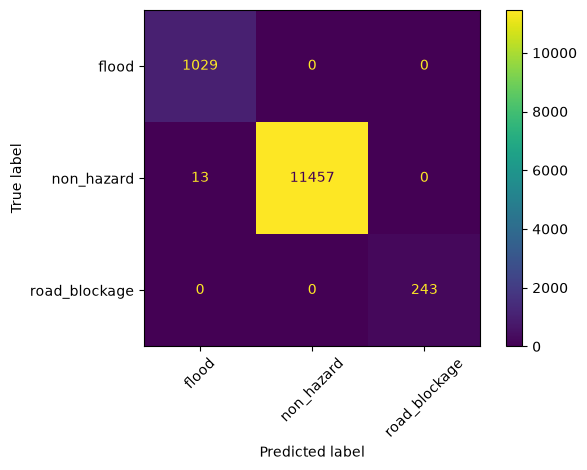

In [6]:
ConfusionMatrixDisplay.from_predictions(y_test, pred, xticks_rotation=45)
plt.tight_layout()
plt.show()

In [7]:
tests = [
    "water is rushing down 5th avenue, cars are stuck up to the doors",
    "huge tree fell across the road on Queens Blvd, nobody can pass",
    "my neighbor is playing loud music again",
    "basement flooded with sewage after the storm",
    "the street is a river near the subway entrance",
    "nice weather today, going for a walk",
    "big branch came down on Atlantic Ave and blocks the lane",
]
probs = clf.predict_proba(vec.transform(tests))
for t, p in zip(tests, probs):
    print(f"{clf.classes_[p.argmax()]:14s} ({p.max():.2f})  {t}")

non_hazard     (0.97)  water is rushing down 5th avenue, cars are stuck up to the doors
non_hazard     (0.94)  huge tree fell across the road on Queens Blvd, nobody can pass
non_hazard     (1.00)  my neighbor is playing loud music again
non_hazard     (0.96)  basement flooded with sewage after the storm
non_hazard     (0.99)  the street is a river near the subway entrance
non_hazard     (0.99)  nice weather today, going for a walk
non_hazard     (0.98)  big branch came down on Atlantic Ave and blocks the lane
